<a href="https://colab.research.google.com/github/SupriyaMourthy/GPZ-AI/blob/main/GPZStudy_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

In [ ]:
import io
df = pd.read_csv(io.BytesIO(uploaded['Study_RandomForest.csv']))
df.head()

,Sl,Grid_Id,Aquifer,Health transition code,Manaveli thickness (m),Ottai thickness (m),WQI_Pre_Class,WQI_Post_Class,GWPI_Class
0,1,GW-01,Alluvium,33,3.21736,26.1801,5,5,3
1,2,GW-02,Alluvium,32,3.22373,26.3507,5,5,3
2,3,GW-03,Alluvium,22,3.23163,26.5346,3,3,3
3,4,GW-04,Cuddalore,33,3.21798,26.5069,5,5,1
4,5,GW-05,Cuddalore,32,3.11786,25.8698,5,5,3


Please upload the `Study_RandomForest.csv` file.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Study_RandomForest.csv to Study_RandomForest.csv


In [ ]:
le = LabelEncoder()
df['Aquifer_encoded'] = le.fit_transform(df['Aquifer'])

In [ ]:
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'Alluvium': np.int64(0), 'Cuddalore': np.int64(1), 'Kadaperikuppam': np.int64(2), 'Thuruvai': np.int64(3), 'Vanur-Ramanathapuram': np.int64(4)}


In [ ]:
features = ['Aquifer_encoded', 'Manaveli thickness (m)', 'Ottai thickness (m)',
            'WQI_Pre_Class', 'WQI_Post_Class', 'GWPI_Class']
target = 'Health transition code'

X = df[features]
y = df[target]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [ ]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)


RandomForestClassifier(n_estimators=200, random_state=42)

In [ ]:
y_pred = rf.predict(X_test)

print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

          22       0.91      0.80      0.85        61
          23       1.00      0.75      0.86         4
          32       0.57      0.57      0.57         7
          33       0.57      0.77      0.65        22

    accuracy                           0.78        94
   macro avg       0.76      0.72      0.73        94
weighted avg       0.81      0.78      0.79        94

Confusion Matrix:
 [[49  0  2 10]
 [ 0  3  0  1]
 [ 1  0  4  2]
 [ 4  0  1 17]]


/tmp/ipython-input-4241798869.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_names, palette='viridis')


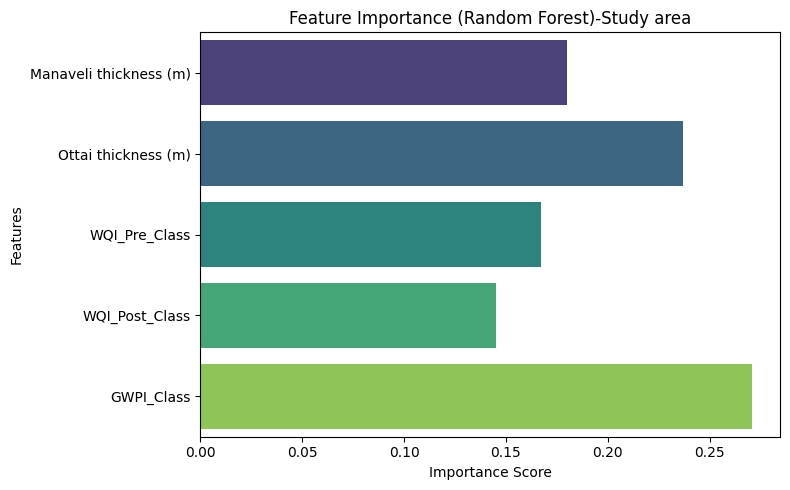

In [ ]:
importances = rf.feature_importances_
feature_names = features

# Plot
plt.figure(figsize=(8,5))
sns.barplot(x=importances, y=feature_names, palette='viridis')
plt.title('Feature Importance (Random Forest)-Study area')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig('feature_importance_plot.png', dpi=600) # Save the plot with 600 dpi
plt.show()

In [ ]:
aquifer_list = df['Aquifer'].unique()

# Example: for Alluvium
df_alluvium = df[df['Aquifer'] == 'Alluvium']



In [ ]:
features = ['Manaveli thickness (m)', 'Ottai thickness (m)',
            'WQI_Pre_Class', 'WQI_Post_Class', 'GWPI_Class']

X = df_alluvium[features]
y = df_alluvium['Health transition code']

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [ ]:
y_pred = rf.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[16  0  1  2]
 [ 1  4  0  2]
 [ 0  0  0  0]
 [ 1  0  1  5]]

Classification Report:
              precision    recall  f1-score   support

          22       0.89      0.84      0.86        19
          23       1.00      0.57      0.73         7
          32       0.00      0.00      0.00         0
          33       0.56      0.71      0.62         7

    accuracy                           0.76        33
   macro avg       0.61      0.53      0.55        33
weighted avg       0.84      0.76      0.78        33



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


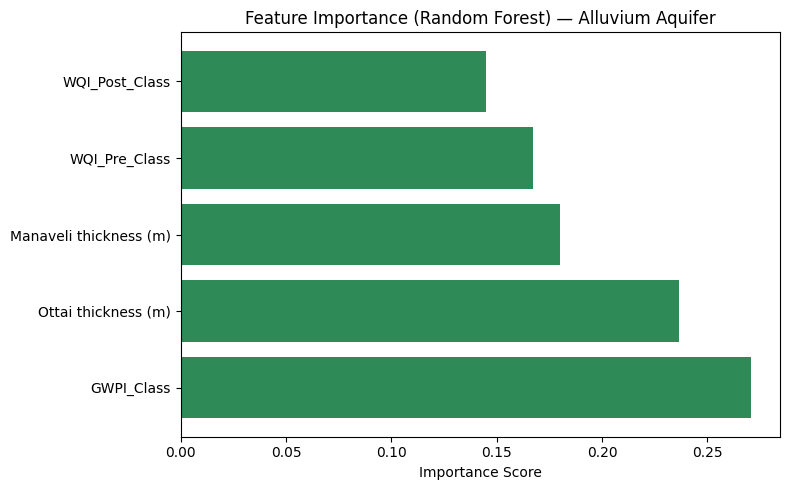

In [ ]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X.columns

plt.figure(figsize=(8, 5))
plt.barh(feature_names[indices], importances[indices], color='seagreen')
plt.xlabel("Importance Score")
plt.title("Feature Importance (Random Forest) — Alluvium Aquifer")
plt.tight_layout()
plt.savefig("RF_feature_importance_alluvium.png", dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
from google.colab import files
files.download("RF_feature_importance_alluvium.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from google.colab import files

# Load your full dataframe if not already loaded
# df = pd.read_csv("Study_RandomForest.csv")

# List of aquifers
aquifers = df['Aquifer'].unique()

# Feature and target
features = ['Manaveli thickness (m)', 'Ottai thickness (m)',
            'WQI_Pre_Class', 'WQI_Post_Class', 'GWPI_Class']
target = 'Health transition code'

# Loop through each aquifer
for aquifer in aquifers:
    df_subset = df[df['Aquifer'] == aquifer]

    X = df_subset[features]
    y = df_subset[target]

    # Skip if too few samples
    if len(df_subset) < 10:
        print(f"Skipping {aquifer}: insufficient data ({len(df_subset)} samples)")
        continue

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42
    )

    # Train Random Forest
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)

    # Get feature importances
    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1]
    feature_names = X.columns

    # Plot
    plt.figure(figsize=(8, 5))
    # Define consistent color for each feature
    feature_color_map = {
        'Manaveli thickness (m)': '#3B738F',  # Blue-gray
        'Ottai thickness (m)': '#287D8E',     # Teal
        'WQI_Pre_Class': '#43AA8B',           # Light green
        'WQI_Post_Class': '#90BE6D',          # Lime green
        'GWPI_Class': '#F9C74F',              # Yellow
    }

    # Get the colors for sorted features
    sorted_features = feature_names[indices]
    bar_colors = [feature_color_map[feat] for feat in sorted_features]

    # Plot with custom colors
    plt.barh(sorted_features, importances[indices], color=bar_colors)
    plt.xlabel("Importance Score")
    plt.title(f"Feature Importance (Random Forest) — {aquifer} Aquifer")
    plt.tight_layout()

    # Save figure
    filename = f"RF_feature_importance_{aquifer.replace(' ', '_')}.png"
    plt.savefig(filename, dpi=600, bbox_inches='tight')
    plt.close()

    # Download
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Restarting the Radom forest
# Install if missing
!pip install seaborn scikit-learn pandas matplotlib

# Import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import os


In [ ]:
# Upload the CSV file in the left panel or via:
from google.colab import files
uploaded = files.upload()

# Load the CSV
df = pd.read_csv("Study_RandomForest.csv")

# Preview
df.head()

Saving Study_RandomForest.csv to Study_RandomForest.csv


,Sl,Grid_Id,Aquifer,Health transition code,Manaveli thickness (m),Ottai thickness (m),WQI_Pre_Class,WQI_Post_Class,GWPI_Class
0,1,GW-01,Alluvium,33,3.21736,26.1801,5,5,3
1,2,GW-02,Alluvium,32,3.22373,26.3507,5,5,3
2,3,GW-03,Alluvium,22,3.23163,26.5346,3,3,3
3,4,GW-04,Cuddalore,33,3.21798,26.5069,5,5,1
4,5,GW-05,Cuddalore,32,3.11786,25.8698,5,5,3


In [ ]:
# Create output folders
os.makedirs("plots", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Viridis palette from darkest to lightest (5 features)
viridis_hex = ['#440154', '#31688e', '#35b779', '#fde725', '#e3f39f']

def run_rf_analysis(df_subset, region_name):
    features = ['Manaveli thickness (m)', 'Ottai thickness (m)',
                'WQI_Pre_Class', 'WQI_Post_Class', 'GWPI_Class']
    target = 'Health transition code'

    X = df_subset[features]
    y = df_subset[target]

    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X, y)

    # Feature importance plot
    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1]
    feature_names = np.array(features)[indices]

    plt.figure(figsize=(8, 5))
    sns.barplot(x=importances[indices], y=feature_names, palette=viridis_hex)
    plt.title(f"Feature Importance - {region_name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig(f"plots/RF_feature_importance_{region_name}.png", dpi=600)
    plt.close()

    # Classification report
    y_pred = rf.predict(X)
    report = classification_report(y, y_pred, output_dict=True)
    report_df = pd.DataFrame(report).transpose()
    report_df['Region'] = region_name
    report_df.reset_index(inplace=True)

    # Save report
    report_df.to_csv(f"reports/RF_Report_{region_name}.csv", index=False)

    # Print Confusion Matrix
    print(f"\n🔹 Confusion Matrix for {region_name}")
    print(confusion_matrix(y, y_pred))

    return report_df


In [ ]:
# Label encode aquifers if not already
if df['Aquifer'].dtype == 'object':
    le = LabelEncoder()
    df['Aquifer'] = le.fit_transform(df['Aquifer'])

# Map encoded aquifers to actual names
aquifer_mapping = {
    0: 'Alluvium', 1: 'Cuddalore', 2: 'Kadaperikuppam',
    3: 'Thuruvai', 4: 'Vanur-Ramanathapuram'
}

# Study area
df['Aquifer_encoded'] = df['Aquifer']
study_report = run_rf_analysis(df, 'StudyArea')

# Per aquifer loop
all_reports = [study_report]
for code, name in aquifer_mapping.items():
    df_subset = df[df['Aquifer_encoded'] == code]
    aquifer_report = run_rf_analysis(df_subset, name)
    all_reports.append(aquifer_report)


/tmp/ipython-input-2458103659.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=feature_names, palette=viridis_hex)



🔹 Confusion Matrix for StudyArea
[[  1   0   0   0   0   0]
 [  0   3   0   0   0   0]
 [  0   0 210   0   0   0]
 [  0   0   0  36   0   0]
 [  0   0   0   0  22   0]
 [  0   0   0   0   0 104]]


/tmp/ipython-input-2458103659.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=feature_names, palette=viridis_hex)



🔹 Confusion Matrix for Alluvium
[[63  0  0  0]
 [ 0 17  0  0]
 [ 0  0  5  0]
 [ 0  0  0 23]]


/tmp/ipython-input-2458103659.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=feature_names, palette=viridis_hex)


...


🔹 Confusion Matrix for Kadaperikuppam
[[ 2  0]
 [ 0 24]]


/tmp/ipython-input-2458103659.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=feature_names, palette=viridis_hex)



🔹 Confusion Matrix for Thuruvai
[[ 1  0  0  0  0]
 [ 0 16  0  0  0]
 [ 0  0  3  0  0]
 [ 0  0  0  3  0]
 [ 0  0  0  0  7]]


/tmp/ipython-input-2458103659.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=feature_names, palette=viridis_hex)



🔹 Confusion Matrix for Vanur-Ramanathapuram
[[37  0  0]
 [ 0  1  0]
 [ 0  0 11]]


In [ ]:
merged_df = pd.concat(all_reports, ignore_index=True)
merged_df.to_csv("Merged_Classification_Report_AllAquifers.csv", index=False)
print("✅ Merged report saved!")

# Zip results
import zipfile

with zipfile.ZipFile("RF_Results_All.zip", "w") as zipf:
    for folder in ['plots', 'reports']:
        for file in os.listdir(folder):
            zipf.write(os.path.join(folder, file))
    zipf.write("Merged_Classification_Report_AllAquifers.csv")


✅ Merged report saved!


In [ ]:
from google.colab import files
files.download("RF_Results_All.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>